In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.shape

(2443651, 9)

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [7]:
list(set(df.dtypes.tolist()))

[dtype('bool'), dtype('float64'), dtype('O'), dtype('int64')]

In [8]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [9]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [10]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [11]:
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [12]:
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

In [13]:
# Verifying that the total number of columns in the dataframe is the sum of object (string) and numerical columns
len(df.columns) == len(df.select_dtypes("object").columns) + len(df.select_dtypes("number").columns)

False

In [14]:
## DATA CLEANING 
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [15]:
# Identifying columns in the dataframe where over 80% of the values are missing
df.columns[df.isnull().mean() > 0.8]

Index([], dtype='object')

In [16]:
# Filtering out columns in the dataframe where more than 80% of the values are missing
df = df[df.columns[df.isnull().mean() < 0.8]]

In [17]:
# Removing the uid" column from the dataframe
df.drop("uid", inplace=True, axis=1)

In [18]:
# Frequency table for categories
category_freq = df['category'].value_counts()
print(category_freq)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [19]:
#Top 5 most listed categories
top5_categories = category_freq.head(5)
print(top5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


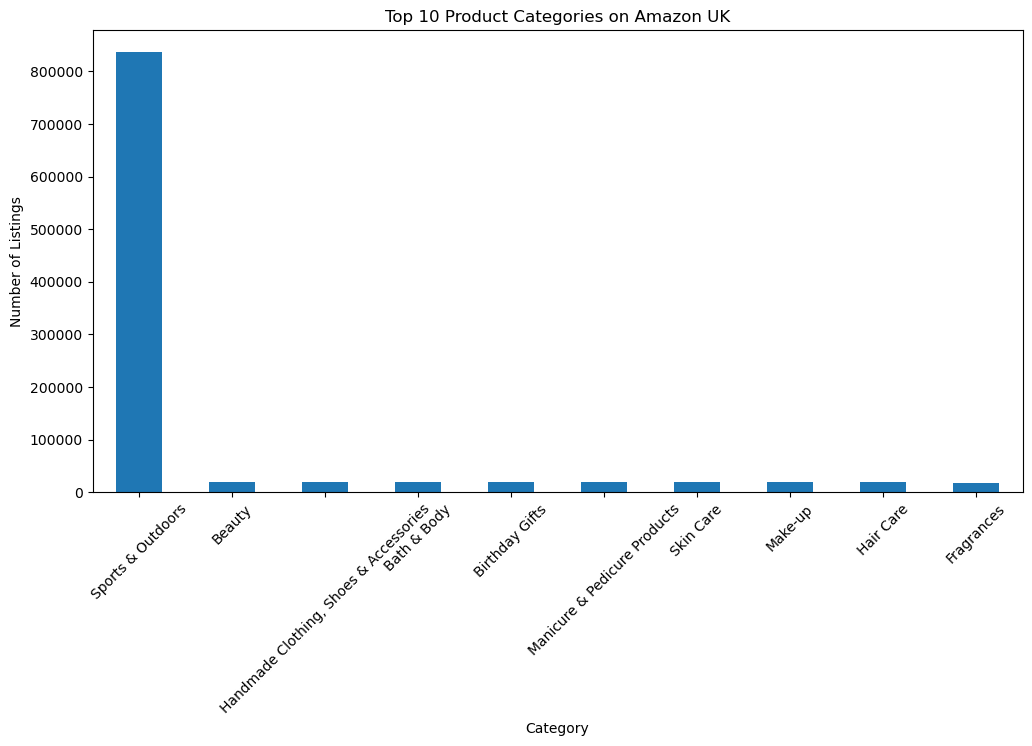

In [20]:
#Bar chart visualization
# Top 10 categories
top10 = category_freq.head(10)

# Plot
plt.figure(figsize=(12,6))

top10.plot(kind='bar')

plt.title('Top 10 Product Categories on Amazon UK')
plt.xlabel('Category')
plt.ylabel('Number of Listings')

plt.xticks(rotation=45)

plt.show()

In [21]:
#Bar chart for category proportion for top 5 categories
top5_prop = (category_freq.head(5) / category_freq.sum()) * 100
print(top5_prop)

category
Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
Name: count, dtype: float64


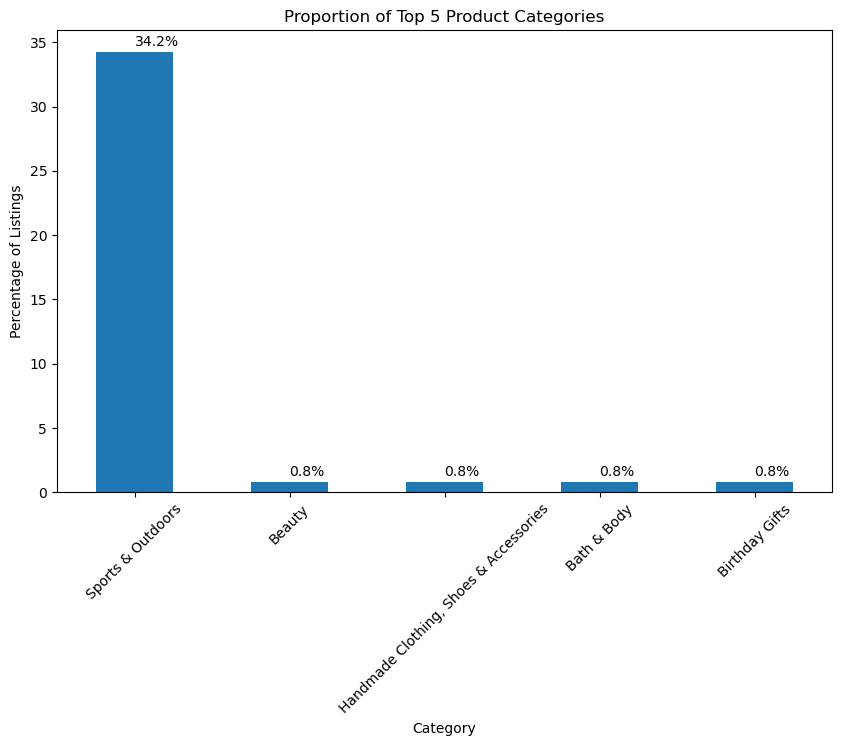

In [22]:
plt.figure(figsize=(10,6))

ax = top5_prop.plot(kind='bar')

plt.title('Proportion of Top 5 Product Categories')
plt.xlabel('Category')
plt.ylabel('Percentage of Listings')
plt.xticks(rotation=45)
# Add labels above bars
for i, value in enumerate(top5_prop):
    plt.text(i, value + 0.5, f'{value:.1f}%')
plt.show()

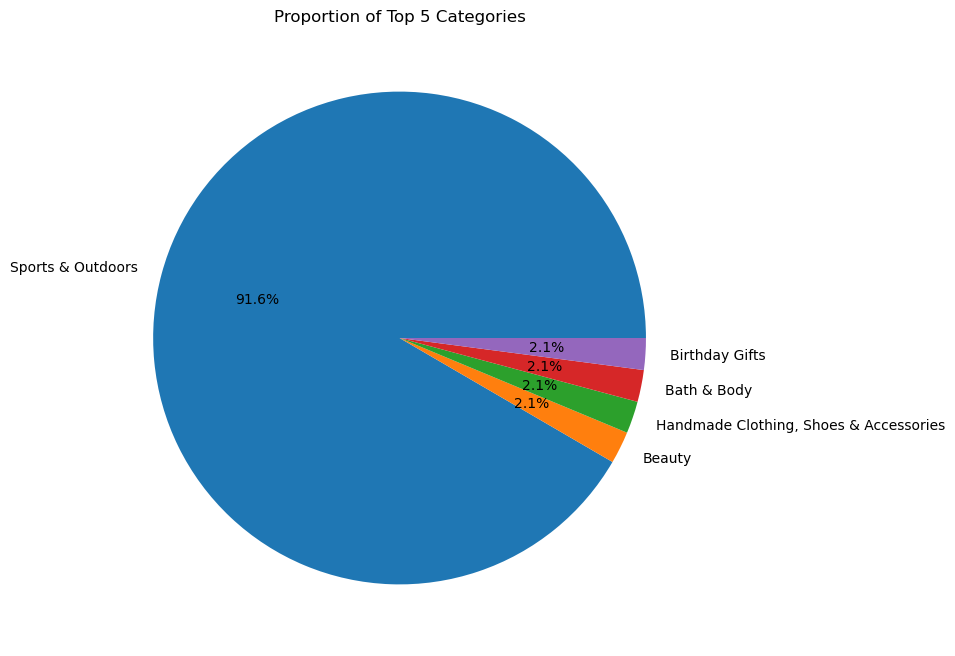

In [23]:
# Top 5 categories
top5 = category_freq.head(5)
plt.figure(figsize=(8,8))
plt.pie(
    top5,
    labels=top5.index,
    autopct='%1.1f%%'
)
plt.title('Proportion of Top 5 Categories')
plt.show()

In [25]:
#measures of centrality
#mean price 
mean_price = df['price'].mean()
print("Mean price:", mean_price)

Mean price: 89.24380943923663


In [26]:
# Median price
median_price = df['price'].median()
print("Median price:", median_price)

Median price: 19.09


In [27]:
# mode price
mode_price = df['price'].mode()[0]
print("Mode price:", mode_price)

Mode price: 9.99


In [ ]:
#Customers generally rate products highly on Amazon UK, with most ratings being close to 4 or 5 stars. This shows an overall positive customer trend. Ratings are fairly consistent, meaning most customers give similar feedback with little variation. The ratings are not normally distributed and instead lean toward higher values, as low ratings are much less common.